In [4]:
import pandas as pd

train = pd.read_csv("../data/raw/train.csv")
test = pd.read_csv("../data/raw/test.csv")

print("TRAIN:", train.shape)
print(train.columns.tolist())
display(train.head(10))

print("TEST:", test.shape)
print(test.columns.tolist())
display(test.head(5))

TRAIN: (81408, 2)
['tweets', 'class']


,tweets,class
0,Be aware dirty step to get money #staylight ...,figurative
1,#sarcasm for #people who don't understand #diy...,figurative
2,@IminworkJeremy @medsingle #DailyMail readers ...,figurative
3,@wilw Why do I get the feeling you like games?...,figurative
4,-@TeacherArthurG @rweingarten You probably jus...,figurative
5,Tune in to Nigezie and be treated to Rachel Pl...,figurative
6,What iz thiz?!?!? A friggin DC love fest??!?!?...,figurative
7,"man, i wish i could sexually harass an intoxic...",figurative
8,@raaachf for the car ride when I get to listen...,figurative
9,Aamir calls #BajrangiBhaijaan as Salman's best...,figurative


TEST: (8128, 2)
['tweets', 'class']


,tweets,class
0,no one ever predicted this was going to happen...,figurative
1,@Stooshie its as closely related as Andrews or...,figurative
2,I find it ironic when Vegans say they love foo...,figurative
3,Quick rt that throwing money vine I've not see...,figurative
4,"yep, keep adding me to your #devops lists.... ...",figurative


In [5]:
print(train["class"].value_counts())
print()
print(test["class"].value_counts())

class
figurative    21238
irony         20894
sarcasm       20681
regular       18595
Name: count, dtype: int64

class
irony         2111
sarcasm       2105
figurative    2044
regular       1859
Name: count, dtype: int64


In [6]:
print("Missing in train:")
print(train.isnull().sum())
print("\nMissing in test:")
print(test.isnull().sum())

print("\nDuplicate tweets in train:", train.duplicated().sum())
print("Duplicate tweets in test:", test.duplicated().sum())

Missing in train:
tweets    0
class     0
dtype: int64

Missing in test:
tweets    2
class     9
dtype: int64

Duplicate tweets in train: 49
Duplicate tweets in test: 1


In [7]:
train = train.dropna().drop_duplicates().reset_index(drop=True)
test = test.dropna().drop_duplicates().reset_index(drop=True)

print("Train:", train.shape)
print("Test:", test.shape)
print(train.isnull().sum().sum(), test.isnull().sum().sum())

Train: (81359, 2)
Test: (8119, 2)
0 0


In [8]:
for c in train["class"].unique():
    print("=====", c.upper(), "=====")
    for t in train[train["class"] == c]["tweets"].sample(5, random_state=1):
        print("-", t)
    print()

===== FIGURATIVE =====
- when you are eating a cookie but you are pinteresting healthy foods #ironic
- @octonion that's what makes America so great isn't it? #sarcasm
- When Instagram publishes an update to its Windows Phone app, you're never disappointed! Nice work guys! #irony #modify #RudyHuyn #king
- * @claire_rio1 @elgee604 @CBCNL No. I'm only pointing out the #irony &amp; #insanity of certain #Atheist #Unitarians accusing me of #blasphemy.
- How #ironic is it that the only person i talk on the phone with doesnt want to anymore and thats the day i lose my voice... Perfect timing.

===== IRONY =====
- @Osty1988 how ironic.. Watching footy, They're singing I'm forever blowing bubbles &amp; there's actual bubbles floatin across the pitch #irony
- International Cat Day on Caturday #caturday #internationalcatday #irony https://t.co/BtKXn7V4Ja
- If you act according to a moral standard, the people who most loudly oppose moral standards go berserk and call you wicked. #KimDavis #Irony
- 

In [9]:
tags = ["irony", "ironic", "sarcasm", "sarcastic"]

for tag in tags:
    has_tag = train["tweets"].str.contains(f"#{tag}", case=False, regex=False)
    print(f"#{tag}")
    print(train[has_tag]["class"].value_counts())
    print()

#irony
class
irony         15843
figurative     7852
Name: count, dtype: int64

#ironic
class
irony         5087
figurative    2792
Name: count, dtype: int64

#sarcasm
class
sarcasm       19595
figurative    10125
Name: count, dtype: int64

#sarcastic
class
sarcasm       1158
figurative     534
Name: count, dtype: int64



In [10]:
import re

leak = re.compile(r"#(irony|ironic|sarcasm|sarcastic)\b", flags=re.IGNORECASE)

def remove_label_tags(text):
    return leak.sub("", text)

train["text_noleak"] = train["tweets"].apply(remove_label_tags)
test["text_noleak"] = test["tweets"].apply(remove_label_tags)

# Check 1: no label hashtag should remain
print("Remaining in train:", train["text_noleak"].str.contains("#sarcas|#ironi", case=False).sum())
print("Remaining in test:", test["text_noleak"].str.contains("#sarcas|#ironi", case=False).sum())

# Check 2: before and after
for i in [1, 20, 100]:
    print("BEFORE:", train["tweets"][i])
    print("AFTER :", train["text_noleak"][i])
    print()

Remaining in train: 89
Remaining in test: 4
BEFORE: #sarcasm for #people who don't understand #diy #artattack http://t.co/rtyYmuDVUS
AFTER :  for #people who don't understand #diy #artattack http://t.co/rtyYmuDVUS

BEFORE: Loving the @BBCSport coverage of #TheOpen  #Sarcasm
AFTER : Loving the @BBCSport coverage of #TheOpen  

BEFORE: @md1uk @Col_Connaughton Sorry for not taking a close part in this keyboard fight, you can win this round if you'd like... #sarcasm
AFTER : @md1uk @Col_Connaughton Sorry for not taking a close part in this keyboard fight, you can win this round if you'd like... 



In [11]:
left = train["text_noleak"].str.extract(r"(#(?:sarcas|ironi)\w*)", flags=re.IGNORECASE)[0].dropna()
print(left.str.lower().value_counts())


0
#ironia                      7
#sarcasticquotes             4
#sarcasmo                    4
#ironically                  4
#ironictiming                3
#ironical                    3
#ironiclisbon                3
#ironing                     3
#ironie                      2
#sarcasticwolf               2
#ironicbeer                  2
#sarcasmatitsfinest          2
#sarcasmstation              2
#sarcasme                    2
#sarcasmlvl424               2
#ironicirony                 2
#sarcasticfringehead         2
#sarcasmoriwillslappeople    2
#sarcasmsign                 2
#ironicpost                  2
#ironicorder                 2
#sarcasmonly                 2
#sarcastictweet              2
#sarcasmfont                 2
#sarcasmislife               2
#sarcasticbitch              2
#sarcasticjokes              1
#sarcasticgirl               1
#sarcasmmode                 1
#sarcastichashtags           1
#ironicart                   1
#ironicangel                 1
#ironi

In [12]:
leak = re.compile(r"#(?!ironing\b)\w*(?:sarcas|ironi)\w*", flags=re.IGNORECASE)

def remove_label_tags(text):
    return leak.sub("", text)

train["text_noleak"] = train["tweets"].apply(remove_label_tags)
test["text_noleak"] = test["tweets"].apply(remove_label_tags)

left = train["text_noleak"].str.extract(r"(#(?:\w*sarcas|\w*ironi)\w*)", flags=re.IGNORECASE)[0].dropna()
print(left.str.lower().value_counts())

0
#ironing    3
Name: count, dtype: int64


In [13]:
for name, df in [("train", train), ("test", test)]:
    length = df["text_noleak"].str.strip().str.len()
    print(name, "- empty:", (length == 0).sum(), "| under 10 characters:", (length < 10).sum())

short = train[train["text_noleak"].str.strip().str.len() < 10]
display(short.head(10))

train - empty: 7 | under 10 characters: 13
test - empty: 1 | under 10 characters: 2


,tweets,class,text_noleak
4231,#Science,figurative,#Science
6397,#irony,figurative,#irony
8834,#ironic,figurative,
11011,#Irony,figurative,#Irony
12961,#Sarcasm,figurative,
17737,#sarcasm,figurative,
26088,#Science,irony,#Science
28509,#irony,irony,#irony
30007,#Ironic,irony,
31121,#ironic,irony,


In [14]:
leak = re.compile(r"#(?!ironing\b)\w*(?:sarcas|iron[iy])\w*", flags=re.IGNORECASE)

def remove_label_tags(text):
    return leak.sub("", text)

train["text_noleak"] = train["tweets"].apply(remove_label_tags)
test["text_noleak"] = test["tweets"].apply(remove_label_tags)

# check: any label-like hashtag still left?
left = train["text_noleak"].str.extract(r"(#\w*(?:sarcas|iron[iy])\w*)", flags=re.IGNORECASE)[0].dropna()
print(left.str.lower().value_counts())

# empty tweets again
for name, df in [("train", train), ("test", test)]:
    print(name, "- empty:", (df["text_noleak"].str.strip().str.len() == 0).sum())

0
#ironing    3
Name: count, dtype: int64
train - empty: 11
test - empty: 2


In [15]:
train = train[train["text_noleak"].str.strip().str.len() > 0].reset_index(drop=True)
test = test[test["text_noleak"].str.strip().str.len() > 0].reset_index(drop=True)

print("Train:", train.shape)
print("Test:", test.shape)
print()
print(train["class"].value_counts())
print()
print(test["class"].value_counts())

Train: (81348, 3)
Test: (8117, 3)

class
figurative    21230
irony         20873
sarcasm       20676
regular       18569
Name: count, dtype: int64

class
irony         2110
sarcasm       2105
figurative    2043
regular       1859
Name: count, dtype: int64


In [16]:
import re

def clean_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # remove links
    text = re.sub(r"@\w+", " ", text)               # remove @mentions
    text = text.replace("&amp;", " and ")           # fix HTML leftover
    text = text.replace("#", " ")                   # keep hashtag words, drop the # sign
    text = re.sub(r"[^a-z\s']", " ", text)          # keep letters and apostrophes only
    text = re.sub(r"\s+", " ", text).strip()        # collapse extra spaces
    return text

train["clean"] = train["text_noleak"].apply(clean_tweet)
test["clean"] = test["text_noleak"].apply(clean_tweet)

for i in [1, 3, 20, 100]:
    print("BEFORE:", train["text_noleak"][i])
    print("AFTER :", train["clean"][i])
    print()

print("Empty after cleaning - train:", (train["clean"] == "").sum(), "| test:", (test["clean"] == "").sum())

BEFORE:  for #people who don't understand #diy #artattack http://t.co/rtyYmuDVUS
AFTER : for people who don't understand diy artattack

BEFORE: @wilw Why do I get the feeling you like games? 
AFTER : why do i get the feeling you like games

BEFORE: Loving the @BBCSport coverage of #TheOpen  
AFTER : loving the coverage of theopen

BEFORE: @md1uk @Col_Connaughton Sorry for not taking a close part in this keyboard fight, you can win this round if you'd like... 
AFTER : sorry for not taking a close part in this keyboard fight you can win this round if you'd like

Empty after cleaning - train: 6 | test: 0


In [17]:
train = train[train["clean"] != ""].reset_index(drop=True)
test = test[test["clean"] != ""].reset_index(drop=True)

print("Train:", train.shape)
print("Test:", test.shape)
print(train["clean"].str.split().str.len().describe())

Train: (81342, 4)
Test: (8117, 4)
count    81342.000000
mean        13.253866
std          5.496761
min          1.000000
25%          9.000000
50%         13.000000
75%         17.000000
max         34.000000
Name: clean, dtype: float64


In [18]:
def add_features(df):
    t = df["text_noleak"]
    df["n_words"] = t.str.split().str.len()
    df["n_chars"] = t.str.len()
    df["n_exclaim"] = t.str.count("!")
    df["n_question"] = t.str.count(r"\?")
    df["n_ellipsis"] = t.str.count(r"\.\.\.|…")
    df["n_caps_words"] = t.str.count(r"\b[A-Z]{2,}\b")
    df["n_hashtags"] = t.str.count("#")
    df["n_mentions"] = t.str.count("@")
    df["has_url"] = t.str.contains("http").astype(int)
    df["n_special"] = t.str.count(r"[^\x00-\x7F]")   # emojis, curly quotes, etc.
    return df

train = add_features(train)
test = add_features(test)

feature_cols = ["n_words", "n_chars", "n_exclaim", "n_question", "n_ellipsis",
                "n_caps_words", "n_hashtags", "n_mentions", "has_url", "n_special"]
display(train.groupby("class")[feature_cols].mean().round(2))

,n_words,n_chars,n_exclaim,n_question,n_ellipsis,n_caps_words,n_hashtags,n_mentions,has_url,n_special
class,,,,,,,,,,
figurative,14.38,92.29,0.25,0.18,0.15,0.28,0.83,0.58,0.25,0.20
irony,15.15,97.61,0.17,0.15,0.13,0.29,0.87,0.55,0.27,0.18
regular,14.34,111.85,0.16,0.09,0.23,0.47,3.41,0.30,0.79,0.43
sarcasm,13.64,87.37,0.33,0.20,0.16,0.29,0.81,0.61,0.24,0.25


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000)

X_train_text = tfidf.fit_transform(train["clean"])   # learn the vocabulary from TRAIN only
X_test_text = tfidf.transform(test["clean"])         # apply the same vocabulary to test

print("Train matrix:", X_train_text.shape)
print("Test matrix:", X_test_text.shape)
print(list(tfidf.get_feature_names_out()[:20]))

Train matrix: (81342, 50000)
Test matrix: (8117, 50000)
['aa', 'aa meeting', 'aaa', 'aaaand', 'aaah', 'aam', 'aap', 'aapl', 'aaptards', 'aaron', 'aaron rodgers', 'ab', 'abandon', 'abandoned', 'abandoning', 'abandons', 'abbott', 'abbott and', 'abbott said', 'abbreviation']


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

y = train["class"]

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_text, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_tr, y_tr)

pred = model.predict(X_val)
print("Validation accuracy:", round(accuracy_score(y_val, pred), 3))
print()
print(classification_report(y_val, pred))

Validation accuracy: 0.526

              precision    recall  f1-score   support

  figurative       0.19      0.16      0.18      4246
       irony       0.47      0.50      0.49      4174
     regular       0.94      0.99      0.96      3714
     sarcasm       0.49      0.51      0.50      4135

    accuracy                           0.53     16269
   macro avg       0.52      0.54      0.53     16269
weighted avg       0.51      0.53      0.52     16269



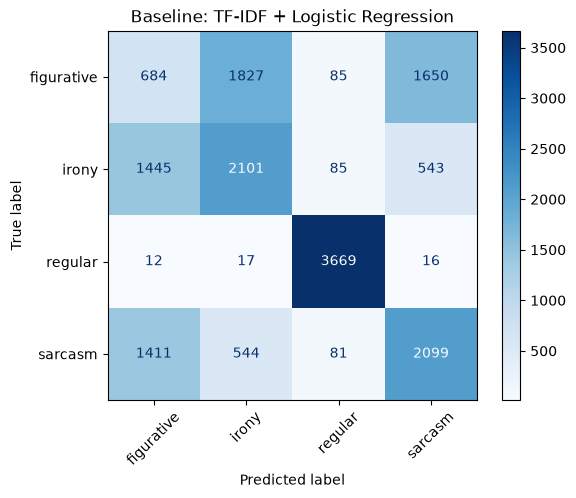

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_val, pred, cmap="Blues", xticks_rotation=45)
plt.title("Baseline: TF-IDF + Logistic Regression")
plt.show()

In [22]:
import numpy as np
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import MaxAbsScaler

# same split as before (same seed, same labels = same rows)
idx_tr, idx_val = train_test_split(np.arange(len(train)), test_size=0.2, random_state=42, stratify=y)

style = train[feature_cols].values
scaler = MaxAbsScaler().fit(style[idx_tr])        # learn scale from the training part only
style_scaled = scaler.transform(style)

# glue the word features and the style features side by side
X_all = hstack([X_train_text, csr_matrix(style_scaled)]).tocsr()

model2 = LogisticRegression(max_iter=1000)
model2.fit(X_all[idx_tr], y.iloc[idx_tr])
pred2 = model2.predict(X_all[idx_val])

print("Baseline (words only):     0.526")
print("Words + style features:   ", round(accuracy_score(y.iloc[idx_val], pred2), 3))
print()
print(classification_report(y.iloc[idx_val], pred2))

Baseline (words only):     0.526
Words + style features:    0.526

              precision    recall  f1-score   support

  figurative       0.19      0.16      0.18      4246
       irony       0.47      0.50      0.48      4174
     regular       0.94      0.99      0.96      3714
     sarcasm       0.49      0.51      0.50      4135

    accuracy                           0.53     16269
   macro avg       0.52      0.54      0.53     16269
weighted avg       0.51      0.53      0.52     16269



In [23]:
import numpy as np

has_irony = train["tweets"].str.contains(r"#iron(?:y|ic)\b", case=False, regex=True)
has_sarc = train["tweets"].str.contains(r"#sarcas(?:m|tic)\b", case=False, regex=True)

train["orig_tag"] = np.select(
    [has_irony & has_sarc, has_irony, has_sarc],
    ["both", "irony tag only", "sarcasm tag only"],
    default="no tag",
)

display(pd.crosstab(train["class"], train["orig_tag"]))

orig_tag,irony tag only,no tag,sarcasm tag only
class,,,
figurative,10610,5,10614
irony,20864,6,0
regular,0,18569,0
sarcasm,0,3,20671


In [24]:
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB

candidates = {
    "Logistic Regression (baseline)": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
    "Complement Naive Bayes": ComplementNB(),
}

for name, m in candidates.items():
    m.fit(X_tr, y_tr)
    p = m.predict(X_val)
    print(name, "->", round(accuracy_score(y_val, p), 3))

Logistic Regression (baseline) -> 0.526
Linear SVM -> 0.482
Complement Naive Bayes -> 0.508


In [25]:
for C in [0.1, 0.3, 1, 3, 10]:
    m = LogisticRegression(C=C, max_iter=1000)
    m.fit(X_tr, y_tr)
    acc_val = accuracy_score(y_val, m.predict(X_val))
    acc_tr = accuracy_score(y_tr, m.predict(X_tr))
    print(f"C={C:<4} train accuracy: {acc_tr:.3f} | validation accuracy: {acc_val:.3f}")

C=0.1  train accuracy: 0.651 | validation accuracy: 0.559
C=0.3  train accuracy: 0.693 | validation accuracy: 0.551
C=1    train accuracy: 0.753 | validation accuracy: 0.526
C=3    train accuracy: 0.806 | validation accuracy: 0.494
C=10   train accuracy: 0.845 | validation accuracy: 0.470


In [36]:
# STEP 1: Word + Character TF-IDF + Style Features

from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import MaxAbsScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Use the SAME train/validation split
tr_text = train["clean"].iloc[idx_tr]
val_text = train["clean"].iloc[idx_val]

# 1. Word-level TF-IDF
word_vec = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=3,
    max_features=5000
)

X_word_tr = word_vec.fit_transform(tr_text)
X_word_val = word_vec.transform(val_text)

# 2. Character-level TF-IDF
char_vec = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(2, 4),
    min_df=5,
    max_features=5000
)

X_char_tr = char_vec.fit_transform(tr_text)
X_char_val = char_vec.transform(val_text)

# 3. Existing style features from your notebook
style_tr = train[feature_cols].iloc[idx_tr].values
style_val = train[feature_cols].iloc[idx_val].values

# Scale style features using training data only
scaler = MaxAbsScaler()
style_tr = scaler.fit_transform(style_tr)
style_val = scaler.transform(style_val)

# 4. Combine all three types of features
X_combined_tr = hstack([
    X_word_tr,
    X_char_tr,
    csr_matrix(style_tr)
]).tocsr()

X_combined_val = hstack([
    X_word_val,
    X_char_val,
    csr_matrix(style_val)
]).tocsr()

print("Combined training shape:", X_combined_tr.shape)
print("Combined validation shape:", X_combined_val.shape)

# 5. Train Logistic Regression
improved_model = LogisticRegression(
    C=0.1,
    max_iter=1000
)

improved_model.fit(X_combined_tr, y.iloc[idx_tr])

# 6. Evaluate
improved_pred = improved_model.predict(X_combined_val)

print("\nImproved Model Results")
print("----------------------")
print(
    "Validation accuracy:",
    round(accuracy_score(y.iloc[idx_val], improved_pred), 3)
)

print("\nClassification Report:")
print(
    classification_report(
        y.iloc[idx_val],
        improved_pred
    )
)

Combined training shape: (65073, 10010)
Combined validation shape: (16269, 10010)

Improved Model Results
----------------------
Validation accuracy: 0.569

Classification Report:
              precision    recall  f1-score   support

  figurative       0.28      0.17      0.21      4246
       irony       0.51      0.60      0.55      4174
     regular       0.91      0.98      0.94      3714
     sarcasm       0.51      0.57      0.54      4135

    accuracy                           0.57     16269
   macro avg       0.55      0.58      0.56     16269
weighted avg       0.54      0.57      0.55     16269



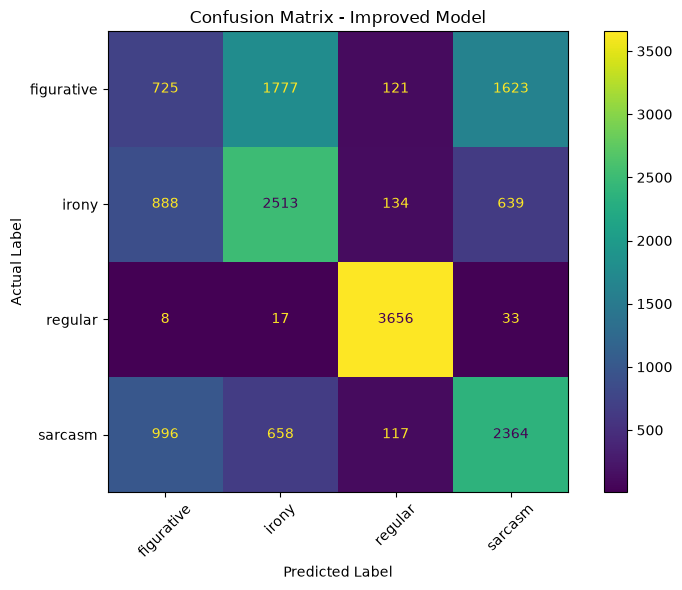

In [37]:
# STEP 2: Confusion Matrix for Error Analysis

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(
    y.iloc[idx_val],
    improved_pred,
    labels=improved_model.classes_
)

# Display it
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=improved_model.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, values_format="d")

plt.title("Confusion Matrix - Improved Model")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
for C in [0.003, 0.01, 0.03, 0.05, 0.1]:
    m = LogisticRegression(C=C, max_iter=1000)
    m.fit(X_tr, y_tr)
    acc_val = accuracy_score(y_val, m.predict(X_val))
    acc_tr = accuracy_score(y_tr, m.predict(X_tr))
    print(f"C={C:<6} train accuracy: {acc_tr:.3f} | validation accuracy: {acc_val:.3f}")

C=0.003  train accuracy: 0.507 | validation accuracy: 0.460
C=0.01   train accuracy: 0.585 | validation accuracy: 0.529
C=0.03   train accuracy: 0.613 | validation accuracy: 0.550
C=0.05   train accuracy: 0.628 | validation accuracy: 0.556
C=0.1    train accuracy: 0.651 | validation accuracy: 0.559


In [27]:
for mf in [5000, 20000, 50000]:
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=mf)
    Xa = vec.fit_transform(train["clean"].iloc[idx_tr])
    Xb = vec.transform(train["clean"].iloc[idx_val])

    m = LogisticRegression(C=0.1, max_iter=1000)
    m.fit(Xa, y.iloc[idx_tr])

    acc_tr = accuracy_score(y.iloc[idx_tr], m.predict(Xa))
    acc_val = accuracy_score(y.iloc[idx_val], m.predict(Xb))
    print(f"max_features={mf:<6} train accuracy: {acc_tr:.3f} | validation accuracy: {acc_val:.3f}")

max_features=5000   train accuracy: 0.622 | validation accuracy: 0.570
max_features=20000  train accuracy: 0.641 | validation accuracy: 0.565
max_features=50000  train accuracy: 0.647 | validation accuracy: 0.560


In [28]:
for mf in [1000, 2000, 3000, 5000]:
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=mf)
    Xa = vec.fit_transform(train["clean"].iloc[idx_tr])
    Xb = vec.transform(train["clean"].iloc[idx_val])

    m = LogisticRegression(C=0.1, max_iter=1000)
    m.fit(Xa, y.iloc[idx_tr])

    acc_tr = accuracy_score(y.iloc[idx_tr], m.predict(Xa))
    acc_val = accuracy_score(y.iloc[idx_val], m.predict(Xb))
    print(f"max_features={mf:<6} train accuracy: {acc_tr:.3f} | validation accuracy: {acc_val:.3f}")

max_features=1000   train accuracy: 0.594 | validation accuracy: 0.568
max_features=2000   train accuracy: 0.607 | validation accuracy: 0.568
max_features=3000   train accuracy: 0.614 | validation accuracy: 0.568
max_features=5000   train accuracy: 0.622 | validation accuracy: 0.570


In [29]:
from scipy.sparse import hstack

tr_text = train["clean"].iloc[idx_tr]
val_text = train["clean"].iloc[idx_val]

word_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=5000)
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=5, max_features=5000)

Xa = hstack([word_vec.fit_transform(tr_text), char_vec.fit_transform(tr_text)]).tocsr()
Xb = hstack([word_vec.transform(val_text), char_vec.transform(val_text)]).tocsr()

for C in [0.05, 0.1, 0.2]:
    m = LogisticRegression(C=C, max_iter=1000)
    m.fit(Xa, y.iloc[idx_tr])
    acc_tr = accuracy_score(y.iloc[idx_tr], m.predict(Xa))
    acc_val = accuracy_score(y.iloc[idx_val], m.predict(Xb))
    print(f"C={C:<5} train accuracy: {acc_tr:.3f} | validation accuracy: {acc_val:.3f}")

C=0.05  train accuracy: 0.617 | validation accuracy: 0.572
C=0.1   train accuracy: 0.631 | validation accuracy: 0.572
C=0.2   train accuracy: 0.645 | validation accuracy: 0.569


TEST accuracy: 0.579

              precision    recall  f1-score   support

  figurative       0.28      0.16      0.20      2043
       irony       0.51      0.62      0.56      2110
     regular       0.94      0.98      0.96      1859
     sarcasm       0.51      0.59      0.55      2105

    accuracy                           0.58      8117
   macro avg       0.56      0.59      0.57      8117
weighted avg       0.55      0.58      0.56      8117



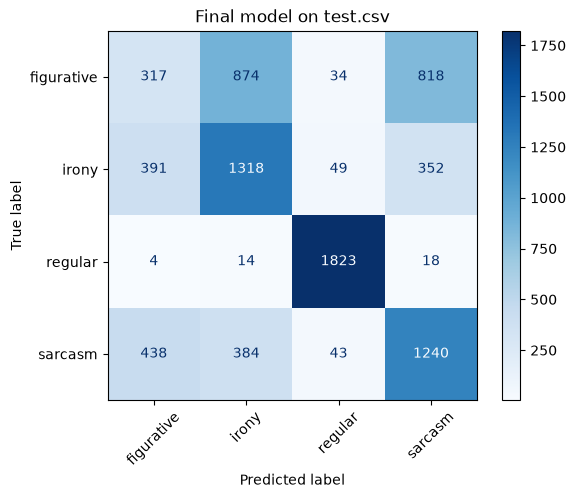

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

final_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=5000)
X_full = final_vec.fit_transform(train["clean"])
X_test_final = final_vec.transform(test["clean"])

final_model = LogisticRegression(C=0.1, max_iter=1000)
final_model.fit(X_full, train["class"])

test_pred = final_model.predict(X_test_final)
print("TEST accuracy:", round(accuracy_score(test["class"], test_pred), 3))
print()
print(classification_report(test["class"], test_pred))

ConfusionMatrixDisplay.from_predictions(test["class"], test_pred, cmap="Blues", xticks_rotation=45)
plt.title("Final model on test.csv")
plt.show()

In [31]:
my_tweets = [
    "Oh great, another Monday. Just what I needed.",
    "Love waiting two hours for a delayed flight",
    "Reading the latest news on the economy http://t.co/abc #politics",
    "It's ironic that the fire station burned down",
]

for t in my_tweets:
    x = final_vec.transform([clean_tweet(t)])
    probs = final_model.predict_proba(x)[0]
    print(t)
    for cls, p in sorted(zip(final_model.classes_, probs), key=lambda z: -z[1]):
        print(f"   {cls:<11} {p:.0%}")
    print()

Oh great, another Monday. Just what I needed.
   sarcasm     76%
   figurative  20%
   irony       3%
   regular     1%

Love waiting two hours for a delayed flight
   sarcasm     49%
   figurative  27%
   irony       14%
   regular     9%

Reading the latest news on the economy http://t.co/abc #politics
   regular     98%
   irony       1%
   figurative  1%
   sarcasm     1%

It's ironic that the fire station burned down
   irony       56%
   figurative  32%
   sarcasm     9%
   regular     3%



In [34]:
def predict_tweet(text):
    text = remove_label_tags(text)          # same first step as training
    x = final_vec.transform([clean_tweet(text)])
    probs = final_model.predict_proba(x)[0]
    print("TWEET:", text.strip())
    for cls, p in sorted(zip(final_model.classes_, probs), key=lambda z: -z[1]):
        print(f"   {cls:<11} {p:.0%}")
    print()

predict_tweet("""Your little help can go a long way

I desperately need an iPhone 18 pro to experience watching reels on the iPhone 18. Only I am short of Rs 4,49,900. Please help me as soon as possible.
Issued in public interest

#sarcasm""")

TWEET: Your little help can go a long way

I desperately need an iPhone 18 pro to experience watching reels on the iPhone 18. Only I am short of Rs 4,49,900. Please help me as soon as possible.
Issued in public interest
   irony       39%
   figurative  33%
   sarcasm     20%
   regular     9%



In [1]:
import re, numpy as np, pandas as pd
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# ---- rebuild the cleaned training data (same steps as before) ----
train = pd.read_csv("../data/raw/train.csv")
train = train.dropna().drop_duplicates().reset_index(drop=True)

leak = re.compile(r"#(?!ironing\b)\w*(?:sarcas|iron[iy])\w*", flags=re.IGNORECASE)
train["text_noleak"] = train["tweets"].apply(lambda t: leak.sub("", t))
train = train[train["text_noleak"].str.strip().str.len() > 0].reset_index(drop=True)

def clean_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = text.replace("&amp;", " and ")
    text = text.replace("#", " ")
    text = re.sub(r"[^a-z\s']", " ", text)
    return re.sub(r"\s+", " ", text).strip()

train["clean"] = train["text_noleak"].apply(clean_tweet)
train = train[train["clean"] != ""].reset_index(drop=True)
print("Train:", train.shape)        # should print (81342, 4)

y = train["class"]
idx_tr, idx_val = train_test_split(np.arange(len(train)), test_size=0.2, random_state=42, stratify=y)

# ---- same 5,000 word features ----
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=5000)
Xa = vec.fit_transform(train["clean"].iloc[idx_tr])
Xb = vec.transform(train["clean"].iloc[idx_val])

# A) Linear SVM with a small C, words only
print("A) Linear SVM, words only")
for C in [0.01, 0.03, 0.1]:
    m = LinearSVC(C=C).fit(Xa, y.iloc[idx_tr])
    print(f"   C={C:<5} validation: {accuracy_score(y.iloc[idx_val], m.predict(Xb)):.3f}")

# B) Words + sentiment scores, Logistic Regression
sia = SentimentIntensityAnalyzer()
def sent(text):
    s = sia.polarity_scores(text)
    return [s["neg"], s["neu"], s["pos"], s["compound"]]

S = np.array([sent(t) for t in train["text_noleak"]])
Xa2 = hstack([Xa, csr_matrix(S[idx_tr])]).tocsr()
Xb2 = hstack([Xb, csr_matrix(S[idx_val])]).tocsr()

print("B) Words + sentiment, Logistic Regression")
m = LogisticRegression(C=0.1, max_iter=1000).fit(Xa2, y.iloc[idx_tr])
print(f"   C=0.1   validation: {accuracy_score(y.iloc[idx_val], m.predict(Xb2)):.3f}")

Train: (81342, 4)
A) Linear SVM, words only
   C=0.01  validation: 0.579
   C=0.03  validation: 0.578
   C=0.1   validation: 0.568
B) Words + sentiment, Logistic Regression
   C=0.1   validation: 0.569


In [2]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report
import joblib, os

# load and clean test.csv with the SAME steps as train
test = pd.read_csv("../data/raw/test.csv").dropna().drop_duplicates().reset_index(drop=True)
test["text_noleak"] = test["tweets"].apply(lambda t: leak.sub("", t))
test = test[test["text_noleak"].str.strip().str.len() > 0].reset_index(drop=True)
test["clean"] = test["text_noleak"].apply(clean_tweet)
test = test[test["clean"] != ""].reset_index(drop=True)
print("Test:", test.shape)          # should be 8117 rows

# final model: 5,000 word features + Linear SVM (C=0.01) with probabilities
final_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=5000)
X_full = final_vec.fit_transform(train["clean"])
X_test = final_vec.transform(test["clean"])

final_model = CalibratedClassifierCV(LinearSVC(C=0.01), cv=5)
final_model.fit(X_full, train["class"])

pred = final_model.predict(X_test)
print("TEST accuracy:", round(accuracy_score(test["class"], pred), 3))
print(classification_report(test["class"], pred))

# save for the app
os.makedirs("../models", exist_ok=True)
joblib.dump({"vectorizer": final_vec, "model": final_model}, "../models/tweet_classifier.joblib")
print("Saved:", round(os.path.getsize("../models/tweet_classifier.joblib") / 1e6, 2), "MB")

Test: (8117, 4)
TEST accuracy: 0.584
              precision    recall  f1-score   support

  figurative       0.29      0.14      0.19      2043
       irony       0.50      0.64      0.56      2110
     regular       0.92      0.99      0.96      1859
     sarcasm       0.51      0.60      0.55      2105

    accuracy                           0.58      8117
   macro avg       0.56      0.59      0.57      8117
weighted avg       0.55      0.58      0.56      8117

Saved: 0.99 MB


In [4]:
import re, joblib

# same cleaning as training
leak = re.compile(r"#(?!ironing\b)\w*(?:sarcas|iron[iy])\w*", flags=re.IGNORECASE)

def clean_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = text.replace("&amp;", " and ")
    text = text.replace("#", " ")
    text = re.sub(r"[^a-z\s']", " ", text)
    return re.sub(r"\s+", " ", text).strip()

bundle = joblib.load("../models/tweet_classifier.joblib")
vec, model = bundle["vectorizer"], bundle["model"]

# (tweet, true label): put your own tweets here, each between the triple quotes
tests = [
    ("""Oh great, another Monday. Just what I needed.""", "sarcasm"),
    ("""Love waiting two hours for a delayed flight""", "sarcasm"),
    ("""Says you hiding behind a fake name""", "irony"),
    ("""Reading the latest news on the economy http://t.co/abc #politics""", "regular"),
    ("""Paste your own tweet here""", "sarcasm"),
]

right = 0
for text, true_label in tests:
    cleaned = clean_tweet(leak.sub("", text))
    probs = model.predict_proba(vec.transform([cleaned]))[0]
    best = model.classes_[probs.argmax()]
    ok = best == true_label
    right += ok
    print("TWEET:", text.strip()[:80])
    print(f"   true: {true_label} | model: {best} ({probs.max():.0%}) | {'OK' if ok else 'WRONG'}")

print(f"\nCorrect: {right} of {len(tests)}")

TWEET: Oh great, another Monday. Just what I needed.
   true: sarcasm | model: sarcasm (72%) | OK
TWEET: Love waiting two hours for a delayed flight
   true: sarcasm | model: sarcasm (62%) | OK
TWEET: Says you hiding behind a fake name
   true: irony | model: irony (63%) | OK
TWEET: Reading the latest news on the economy http://t.co/abc #politics
   true: regular | model: regular (95%) | OK
TWEET: Paste your own tweet here
   true: sarcasm | model: irony (52%) | WRONG

Correct: 4 of 5


In [5]:
import joblib

# Save the model
joblib.dump(final_model, 'tweet_classifier.joblib')
print("Model saved as tweet_classifier.joblib")

# Save the vectorizer (important!)
joblib.dump(final_vec, 'tweet_vectorizer.joblib')
print("Vectorizer saved as tweet_vectorizer.joblib")

Model saved as tweet_classifier.joblib
Vectorizer saved as tweet_vectorizer.joblib


In [6]:
pip freeze | findstr /i "scikit-learn joblib numpy scipy streamlit pandas"

joblib==1.5.3
numpy==2.5.2
pandas==3.0.5
scikit-learn==1.9.0
scipy==1.18.0
streamlit==1.64.0
Note: you may need to restart the kernel to use updated packages.


In [1]:
import re, os, gzip, urllib.request
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# ---- rebuild cleaned training data (same steps as your TF-IDF model) ----
train = pd.read_csv("../data/raw/train.csv").dropna().drop_duplicates().reset_index(drop=True)
leak = re.compile(r"#(?!ironing\b)\w*(?:sarcas|iron[iy])\w*", flags=re.IGNORECASE)
train["text_noleak"] = train["tweets"].apply(lambda t: leak.sub("", t))
train = train[train["text_noleak"].str.strip().str.len() > 0].reset_index(drop=True)

def clean_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = text.replace("&amp;", " and ")
    text = text.replace("#", " ")
    text = re.sub(r"[^a-z\s']", " ", text)
    return re.sub(r"\s+", " ", text).strip()

train["clean"] = train["text_noleak"].apply(clean_tweet)
train = train[train["clean"] != ""].reset_index(drop=True)
print("Train:", train.shape)   # should be (81342, 4)

y = train["class"]
idx_tr, idx_val = train_test_split(np.arange(len(train)), test_size=0.2, random_state=42, stratify=y)

# ---- download pretrained GloVe-Twitter vectors (104 MB, one-time, no compiler needed) ----
os.makedirs("../models/embeddings", exist_ok=True)
glove_path = "../models/embeddings/glove-twitter-25.gz"
url = "https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-twitter-25/glove-twitter-25.gz"

if not os.path.exists(glove_path):
    print("Downloading GloVe-Twitter-25 (about 104 MB)...")
    urllib.request.urlretrieve(url, glove_path)
    print("Done.")
else:
    print("Already downloaded.")

# ---- parse the file ourselves: plain text, no gensim needed ----
print("Loading vectors into memory...")
words, vecs = [], []
with gzip.open(glove_path, "rt", encoding="utf-8") as f:
    next(f)  # skip header line: "vocab_size dim"
    for line in f:
        parts = line.rstrip().split(" ")
        words.append(parts[0])
        vecs.append(np.asarray(parts[1:], dtype=np.float32))

glove_matrix = np.vstack(vecs)
glove_index = {w: i for i, w in enumerate(words)}
DIM = glove_matrix.shape[1]
print(f"Loaded {len(words):,} word vectors, {DIM} dimensions each.")

# ---- average the word vectors in each tweet ----
def tweet_to_vector(text):
    idxs = [glove_index[w] for w in text.split() if w in glove_index]
    return glove_matrix[idxs].mean(axis=0) if idxs else np.zeros(DIM)

print("Building tweet vectors...")
X_glove = np.array([tweet_to_vector(t) for t in train["clean"]])
print("Embedding matrix shape:", X_glove.shape)

Xa, Xb = X_glove[idx_tr], X_glove[idx_val]
ya, yb = y.iloc[idx_tr], y.iloc[idx_val]

model = LogisticRegression(max_iter=1000)
model.fit(Xa, ya)
pred = model.predict(Xb)

print("\n=== GloVe-Twitter-25 (averaged) + Logistic Regression ===")
print("Validation accuracy:", round(accuracy_score(yb, pred), 3))
print(classification_report(yb, pred))
print("For comparison, your TF-IDF model scored 0.570 on this same validation split.")

Train: (81342, 4)
Done.
Loading vectors into memory...
Loaded 1,193,514 word vectors, 25 dimensions each.
Building tweet vectors...
Embedding matrix shape: (81342, 25)

=== GloVe-Twitter-25 (averaged) + Logistic Regression ===
Validation accuracy: 0.44
              precision    recall  f1-score   support

  figurative       0.30      0.15      0.20      4246
       irony       0.41      0.48      0.44      4174
     regular       0.59      0.66      0.62      3714
     sarcasm       0.41      0.49      0.45      4135

    accuracy                           0.44     16269
   macro avg       0.43      0.45      0.43     16269
weighted avg       0.42      0.44      0.42     16269

For comparison, your TF-IDF model scored 0.570 on this same validation split.


In [2]:
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

# A) Linear SVM on GloVe alone (fair comparison to your TF-IDF SVM)
print("A) Linear SVM on GloVe-25 alone")
for C in [0.01, 0.1, 1]:
    m = LinearSVC(C=C)
    m.fit(X_glove[idx_tr], y.iloc[idx_tr])
    acc = accuracy_score(y.iloc[idx_val], m.predict(X_glove[idx_val]))
    print(f"   C={C:<5} validation: {acc:.3f}")

# B) TF-IDF + GloVe combined (extend, not replace)
word_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=5000)
Xa_tfidf = word_vec.fit_transform(train["clean"].iloc[idx_tr])
Xb_tfidf = word_vec.transform(train["clean"].iloc[idx_val])

Xa_combo = hstack([Xa_tfidf, csr_matrix(X_glove[idx_tr])]).tocsr()
Xb_combo = hstack([Xb_tfidf, csr_matrix(X_glove[idx_val])]).tocsr()

print("\nB) TF-IDF + GloVe combined, Linear SVM")
for C in [0.01, 0.03]:
    m = LinearSVC(C=C)
    m.fit(Xa_combo, y.iloc[idx_tr])
    acc = accuracy_score(y.iloc[idx_val], m.predict(Xb_combo))
    print(f"   C={C:<5} validation: {acc:.3f}")

print("\nFor reference: TF-IDF alone scored 0.570 (LR) / 0.579 (SVM) on this split.")

A) Linear SVM on GloVe-25 alone
   C=0.01  validation: 0.438
   C=0.1   validation: 0.438
   C=1     validation: 0.438

B) TF-IDF + GloVe combined, Linear SVM
   C=0.01  validation: 0.577
   C=0.03  validation: 0.582

For reference: TF-IDF alone scored 0.570 (LR) / 0.579 (SVM) on this split.


In [3]:
import gzip, os, urllib.request
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix
from sklearn.metrics import accuracy_score, classification_report

DIM_NAME = "glove-twitter-100"   # ~390 MB download; use glove-twitter-25 to skip
path = f"../models/embeddings/{DIM_NAME}.gz"
url = f"https://github.com/RaRe-Technologies/gensim-data/releases/download/{DIM_NAME}/{DIM_NAME}.gz"
if not os.path.exists(path):
    print("Downloading", DIM_NAME, "...")
    urllib.request.urlretrieve(url, path)

# keep only words that appear in our tweets (saves memory)
vocab = set(w for t in train["clean"] for w in t.split())
words, vecs = [], []
with gzip.open(path, "rt", encoding="utf-8") as f:
    next(f)
    for line in f:
        parts = line.rstrip().split(" ")
        if parts[0] in vocab:
            words.append(parts[0]); vecs.append(np.asarray(parts[1:], dtype=np.float32))
M = np.vstack(vecs); idx = {w: i for i, w in enumerate(words)}; D = M.shape[1]
print(f"Kept {len(words):,} of {len(vocab):,} vocab words, {D} dims")

def pool(text):                      # mean + max pooling -> 2*D features
    ii = [idx[w] for w in text.split() if w in idx]
    if not ii: return np.zeros(2 * D)
    v = M[ii]
    return np.concatenate([v.mean(axis=0), v.max(axis=0)])

X_emb = np.array([pool(t) for t in train["clean"]])
sc = StandardScaler().fit(X_emb[idx_tr])
X_emb = sc.transform(X_emb)

print("\nA) Embeddings alone, Linear SVM")
for C in [0.01, 0.1, 1]:
    m = LinearSVC(C=C, max_iter=5000).fit(X_emb[idx_tr], y.iloc[idx_tr])
    print(f"   C={C:<5} validation: {accuracy_score(y.iloc[idx_val], m.predict(X_emb[idx_val])):.3f}")

print("\nB) TF-IDF + embeddings, Linear SVM")
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=5000)
Xa_t = vec.fit_transform(train["clean"].iloc[idx_tr]); Xb_t = vec.transform(train["clean"].iloc[idx_val])
for w in [0.1, 0.3]:                 # weight on the embedding block
    Xa = hstack([Xa_t, csr_matrix(X_emb[idx_tr] * w)]).tocsr()
    Xb = hstack([Xb_t, csr_matrix(X_emb[idx_val] * w)]).tocsr()
    for C in [0.01, 0.03]:
        m = LinearSVC(C=C, max_iter=5000).fit(Xa, y.iloc[idx_tr])
        print(f"   weight={w} C={C:<5} validation: {accuracy_score(y.iloc[idx_val], m.predict(Xb)):.3f}")
print("\nReference: TF-IDF SVM 0.579 | TF-IDF + GloVe-25 0.582")

Kept 40,419 of 63,369 vocab words, 100 dims

A) Embeddings alone, Linear SVM
   C=0.01  validation: 0.506
   C=0.1   validation: 0.506
   C=1     validation: 0.506

B) TF-IDF + embeddings, Linear SVM
   weight=0.1 C=0.01  validation: 0.575
   weight=0.1 C=0.03  validation: 0.581
   weight=0.3 C=0.01  validation: 0.572
   weight=0.3 C=0.03  validation: 0.580

Reference: TF-IDF SVM 0.579 | TF-IDF + GloVe-25 0.582


In [4]:
import gzip, joblib
from sklearn.linear_model import LogisticRegression

# ---- load test exactly as in cell 32 ----
test = pd.read_csv("../data/raw/test.csv").dropna().drop_duplicates().reset_index(drop=True)
test["text_noleak"] = test["tweets"].apply(lambda t: leak.sub("", t))
test = test[test["text_noleak"].str.strip().str.len() > 0].reset_index(drop=True)
test["clean"] = test["text_noleak"].apply(clean_tweet)
test = test[test["clean"] != ""].reset_index(drop=True)
print("Test:", test.shape)   # should be (8117, 4)

# ---- GloVe-100, vocab from train + test ----
path = "../models/embeddings/glove-twitter-100.gz"
vocab = set(w for t in pd.concat([train["clean"], test["clean"]]) for w in t.split())
words, vecs = [], []
with gzip.open(path, "rt", encoding="utf-8") as f:
    next(f)
    for line in f:
        parts = line.rstrip().split(" ")
        if parts[0] in vocab:
            words.append(parts[0]); vecs.append(np.asarray(parts[1:], dtype=np.float32))
M = np.vstack(vecs); idx = {w: i for i, w in enumerate(words)}; D = M.shape[1]

def pool(text):
    ii = [idx[w] for w in text.split() if w in idx]
    if not ii: return np.zeros(2 * D)
    v = M[ii]
    return np.concatenate([v.mean(axis=0), v.max(axis=0)])

Xe_tr = np.array([pool(t) for t in train["clean"]])
Xe_te = np.array([pool(t) for t in test["clean"]])
sc = StandardScaler().fit(Xe_tr)
Xe_tr, Xe_te = sc.transform(Xe_tr), sc.transform(Xe_te)
ytr, yte = train["class"], test["class"]

# 1) GloVe-100 alone (Logistic Regression)
m1 = LogisticRegression(C=0.1, max_iter=2000).fit(Xe_tr, ytr)
p1 = m1.predict(Xe_te)
print("\n=== GloVe-100 alone, test ===")
print("accuracy:", round(accuracy_score(yte, p1), 3))
print(classification_report(yte, p1))

# 2) TF-IDF + GloVe-100 (extend)
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=5000)
Xt_tr = vec.fit_transform(train["clean"]); Xt_te = vec.transform(test["clean"])
Xc_tr = hstack([Xt_tr, csr_matrix(Xe_tr * 0.1)]).tocsr()
Xc_te = hstack([Xt_te, csr_matrix(Xe_te * 0.1)]).tocsr()
m2 = LinearSVC(C=0.03, max_iter=5000).fit(Xc_tr, ytr)
p2 = m2.predict(Xc_te)
print("\n=== TF-IDF + GloVe-100, test ===")
print("accuracy:", round(accuracy_score(yte, p2), 3))
print(classification_report(yte, p2))
print("Before (TF-IDF + Linear SVM, test): 0.584")

# save for the app
os.makedirs("../models", exist_ok=True)
np.savez_compressed("../models/glove100_subset.npz", words=np.array(words), vectors=M)
joblib.dump({"tfidf": vec, "scaler": sc, "model": m2, "embed_weight": 0.1},
            "../models/tweet_classifier_glove.joblib")
print("Saved.")

Test: (8117, 4)

=== GloVe-100 alone, test ===
accuracy: 0.5
              precision    recall  f1-score   support

  figurative       0.29      0.16      0.21      2043
       irony       0.45      0.54      0.49      2110
     regular       0.72      0.81      0.76      1859
     sarcasm       0.46      0.52      0.49      2105

    accuracy                           0.50      8117
   macro avg       0.48      0.51      0.49      8117
weighted avg       0.47      0.50      0.48      8117


=== TF-IDF + GloVe-100, test ===
accuracy: 0.591
              precision    recall  f1-score   support

  figurative       0.26      0.10      0.15      2043
       irony       0.51      0.66      0.58      2110
     regular       0.91      1.00      0.95      1859
     sarcasm       0.52      0.64      0.57      2105

    accuracy                           0.59      8117
   macro avg       0.55      0.60      0.56      8117
weighted avg       0.54      0.59      0.55      8117

Before (TF-IDF + Li

In [5]:
old = joblib.load("../models/tweet_classifier.joblib")
old_vec, old_model = old["vectorizer"], old["model"]

samples = [
    ("Oh great, another Monday. Just what I needed.", "sarcasm"),
    ("Love waiting two hours for a delayed flight", "sarcasm"),
    ("Says you hiding behind a fake name", "irony"),
    ("Reading the latest news on the economy http://t.co/abc #politics", "regular"),
]
for text, true in samples:
    c = clean_tweet(leak.sub("", text))
    old_pred = old_model.predict(old_vec.transform([c]))[0]
    xe = sc.transform(pool(c).reshape(1, -1)) * 0.1
    new_pred = m2.predict(hstack([vec.transform([c]), csr_matrix(xe)]).tocsr())[0]
    print(f"{text[:60]}\n   true: {true} | before: {old_pred} | after: {new_pred}\n")

Oh great, another Monday. Just what I needed.
   true: sarcasm | before: sarcasm | after: sarcasm

Love waiting two hours for a delayed flight
   true: sarcasm | before: sarcasm | after: sarcasm

Says you hiding behind a fake name
   true: irony | before: irony | after: irony

Reading the latest news on the economy http://t.co/abc #poli
   true: regular | before: regular | after: regular



In [6]:
old_pred_test = old_model.predict(old_vec.transform(test["clean"]))
new_pred_test = p2   # from the final test cell

yt = test["class"].values
changed = old_pred_test != new_pred_test
fixed  = changed & (new_pred_test == yt)   # old wrong, new right
broken = changed & (old_pred_test == yt)   # old right, new wrong

print(f"Predictions that differ: {changed.sum()} of {len(test)}")
print(f"  new right, old wrong: {fixed.sum()}")
print(f"  old right, new wrong: {broken.sum()}")

for title, mask in [("NEW RIGHT, OLD WRONG", fixed), ("OLD RIGHT, NEW WRONG", broken)]:
    print(f"\n=== {title} ===")
    for i in np.where(mask)[0][:4]:
        print(f"- {test['tweets'].iloc[i][:100]!r}\n  true: {yt[i]} | before: {old_pred_test[i]} | after: {new_pred_test[i]}")

Predictions that differ: 1007 of 8117
  new right, old wrong: 369
  old right, new wrong: 317

=== NEW RIGHT, OLD WRONG ===
- 'When one of your tweets gets more favorites than you have followers... #irony'
  true: figurative | before: irony | after: figurative
- 'Terrelle Pryor and Braxton Miller Both Wide Receivers Now! #Ironic'
  true: figurative | before: irony | after: figurative
- 'Gas tank cover gone? Just stuff plastic bags into it! Genius!\n#stupid #fail #wow #sarcasm https://t.'
  true: figurative | before: sarcasm | after: figurative
- '@recserv totally love that your smoothie shop got rid of styrofoam, simultaneously disappointed ther'
  true: figurative | before: sarcasm | after: figurative

=== OLD RIGHT, NEW WRONG ===
- "Quick rt that throwing money vine I've not seen it 30 times in the last 30 seconds #sarcasm"
  true: figurative | before: figurative | after: sarcasm
- '@theandyboyd You say, via twitter. #irony'
  true: figurative | before: figurative | after: irony
- "C

In [7]:
%pip install gensim

  Using cached gensim-4.4.0.tar.gz (23.3 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Failed to build gensim
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Building wheel for gensim (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [806 lines of output]
      C:\Users\user\AppData\Local\Temp\pip-build-env-jipggmrq\overlay\Lib\site-packages\setuptools\_distutils\dist.py:318: UserWarning: Unknown distribution option: 'test_suite'
        warnings.warn(msg)
      C:\Users\user\AppData\Local\Temp\pip-build-env-jipggmrq\overlay\Lib\site-packages\setuptools\_distutils\dist.py:318: UserWarning: Unknown distribution option: 'tests_require'
        warnings.warn(msg)
      running bdist_wheel
      running build
      running build_py
      creating build\lib.win-amd64-cpython-314\gensim
      copying gensim\downloader.py -> build\lib.win-amd64-cpython-314\gensim
      copying gensim\interfaces.py -> build\lib.win-amd64-cpython-314\gensim
      copying gensim\matutils.py -> build\lib.win-amd64-cpython-314\gensim
      copying gensim\nosy.py -> build\lib.win-amd64-cpython-314\gensim
     